# Лабораторная работа №4: шум в изображениях — восстановление погодных карт; аугментация признаков

**Тема №23:** Анализ и прогноз погоды — *«Погода как знак и алгоритм»*

Лаб. 4 (`L28_SAD_LAB_NR_4_…PRELUCRARE_IMAGINI` в материалах к экзамену): изображение портится гауссовым шумом (σ = 20 и 50 по шкале 0–255) и восстанавливается классическими фильтрами (гауссов, билатеральный, Non-Local Means) и **автоэнкодером**. Качество меряется PSNR, SSIM и MSE; смотрим, как метрики меняются с эпохами и скоростью обучения, где автоэнкодер недообучается и переобучается. Вторая часть лабы — **аугментация** в изображениях и в признаках, и чем аугментация отличается от RAG.

**Наши изображения — погодные карты.** У преподавателя — фотографии. У нас — суточные **карты реанализа ERA5** над Молдовой: сетка 0.25° (≈ 28 км), 13 × 15 точек, 2024 год (366 дней). Переменные — давление, температура, облачность, осадки (`src/download_maps.py`, Open-Meteo). Каждая карта — изображение, у которого «пиксель» — значение поля. Так вопрос лабы *«что теряется и что сохраняется?»* получает метеорологический смысл: сохранился ли центр циклона, не размыло ли ливневую ячейку.

| Часть | Лабораторная | У нас |
|---|---|---|
| 1 | изображение и гауссов шум σ = 20 / 50 | 4 поля × 366 карт, шум в шкале 0–255 |
| 2 | Gaussian blur, Bilateral, Non-Local Means; PSNR, SSIM, MSE | те же методы (`scikit-image`) на 92 картах октября–декабря |
| 3 | автоэнкодер: метрики по эпохам, скорость обучения, недо/переобучение | denoising-автоэнкодер (MLP 195 → 128 → 32 → 128 → 195), обучение январь–сентябрь |
| 4 | «Ce se pierde? Ce se păstrează?» | центр циклона на картах давления, пики и «дождь/сухо» на картах осадков |
| 5 | аугментация в изображениях и в признаках; RAG | шум как аугментация для автоэнкодера; шум, mixup и выпадение признаков для нашей модели дождя |

In [1]:
import sys, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from skimage.filters import gaussian
from skimage.restoration import denoise_bilateral, denoise_nl_means
from skimage.metrics import peak_signal_noise_ratio as psnr, structural_similarity as ssim, mean_squared_error as mse
from sklearn.neural_network import MLPRegressor

warnings.filterwarnings("ignore")
FIG = ROOT / "figures"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
SEED = 42
def save(name):
    plt.savefig(FIG / f"{name}.png"); plt.show()

M = np.load(ROOT / "data" / "raw" / "maps" / "era5_maps_2024.npz", allow_pickle=True)
LAT, LON, DATES = M["lat"], M["lon"], pd.to_datetime(M["dates"])
VARS = {"pressure_msl_mean": ("Давление, гПа", "RdBu_r"), "temperature_2m_mean": ("Температура, °C", "coolwarm"),
        "cloud_cover_mean": ("Облачность, %", "Greys"), "precipitation_sum": ("Осадки, мм", "Blues")}
raw = {v: M[v] for v in VARS}
# per-variable scaling to [0, 1] (precipitation: square root — the field is very skewed), like an 8-bit image / 255
lo = {v: np.nanpercentile(raw[v], 0.5) for v in VARS}; hi = {v: np.nanpercentile(raw[v], 99.5) for v in VARS}
def to_img(v, a):
    a = np.sqrt(np.clip(a, 0, None)) if v == "precipitation_sum" else a
    l, h = (np.sqrt(max(lo[v], 0)), np.sqrt(hi[v])) if v == "precipitation_sum" else (lo[v], hi[v])
    return np.clip((a - l) / (h - l), 0, 1)
def from_img(v, x):
    l, h = (np.sqrt(max(lo[v], 0)), np.sqrt(hi[v])) if v == "precipitation_sum" else (lo[v], hi[v])
    y = x * (h - l) + l
    return y ** 2 if v == "precipitation_sum" else y
IMG = {v: to_img(v, raw[v]) for v in VARS}
train_idx = np.where(DATES.month <= 9)[0]; test_idx = np.where(DATES.month >= 10)[0]
H, W_ = IMG["pressure_msl_mean"].shape[1:]
print(f"{len(DATES)} карт {H}×{W_} на переменную; пропусков: {sum(int(np.isnan(raw[v]).sum()) for v in VARS)}; "
      f"обучение автоэнкодера: {len(train_idx)} дней (янв–сен), проверка: {len(test_idx)} дней (окт–дек)")

366 карт 13×15 на переменную; пропусков: 0; обучение автоэнкодера: 274 дней (янв–сен), проверка: 92 дней (окт–дек)


---
# 1. Погодные карты и гауссов шум

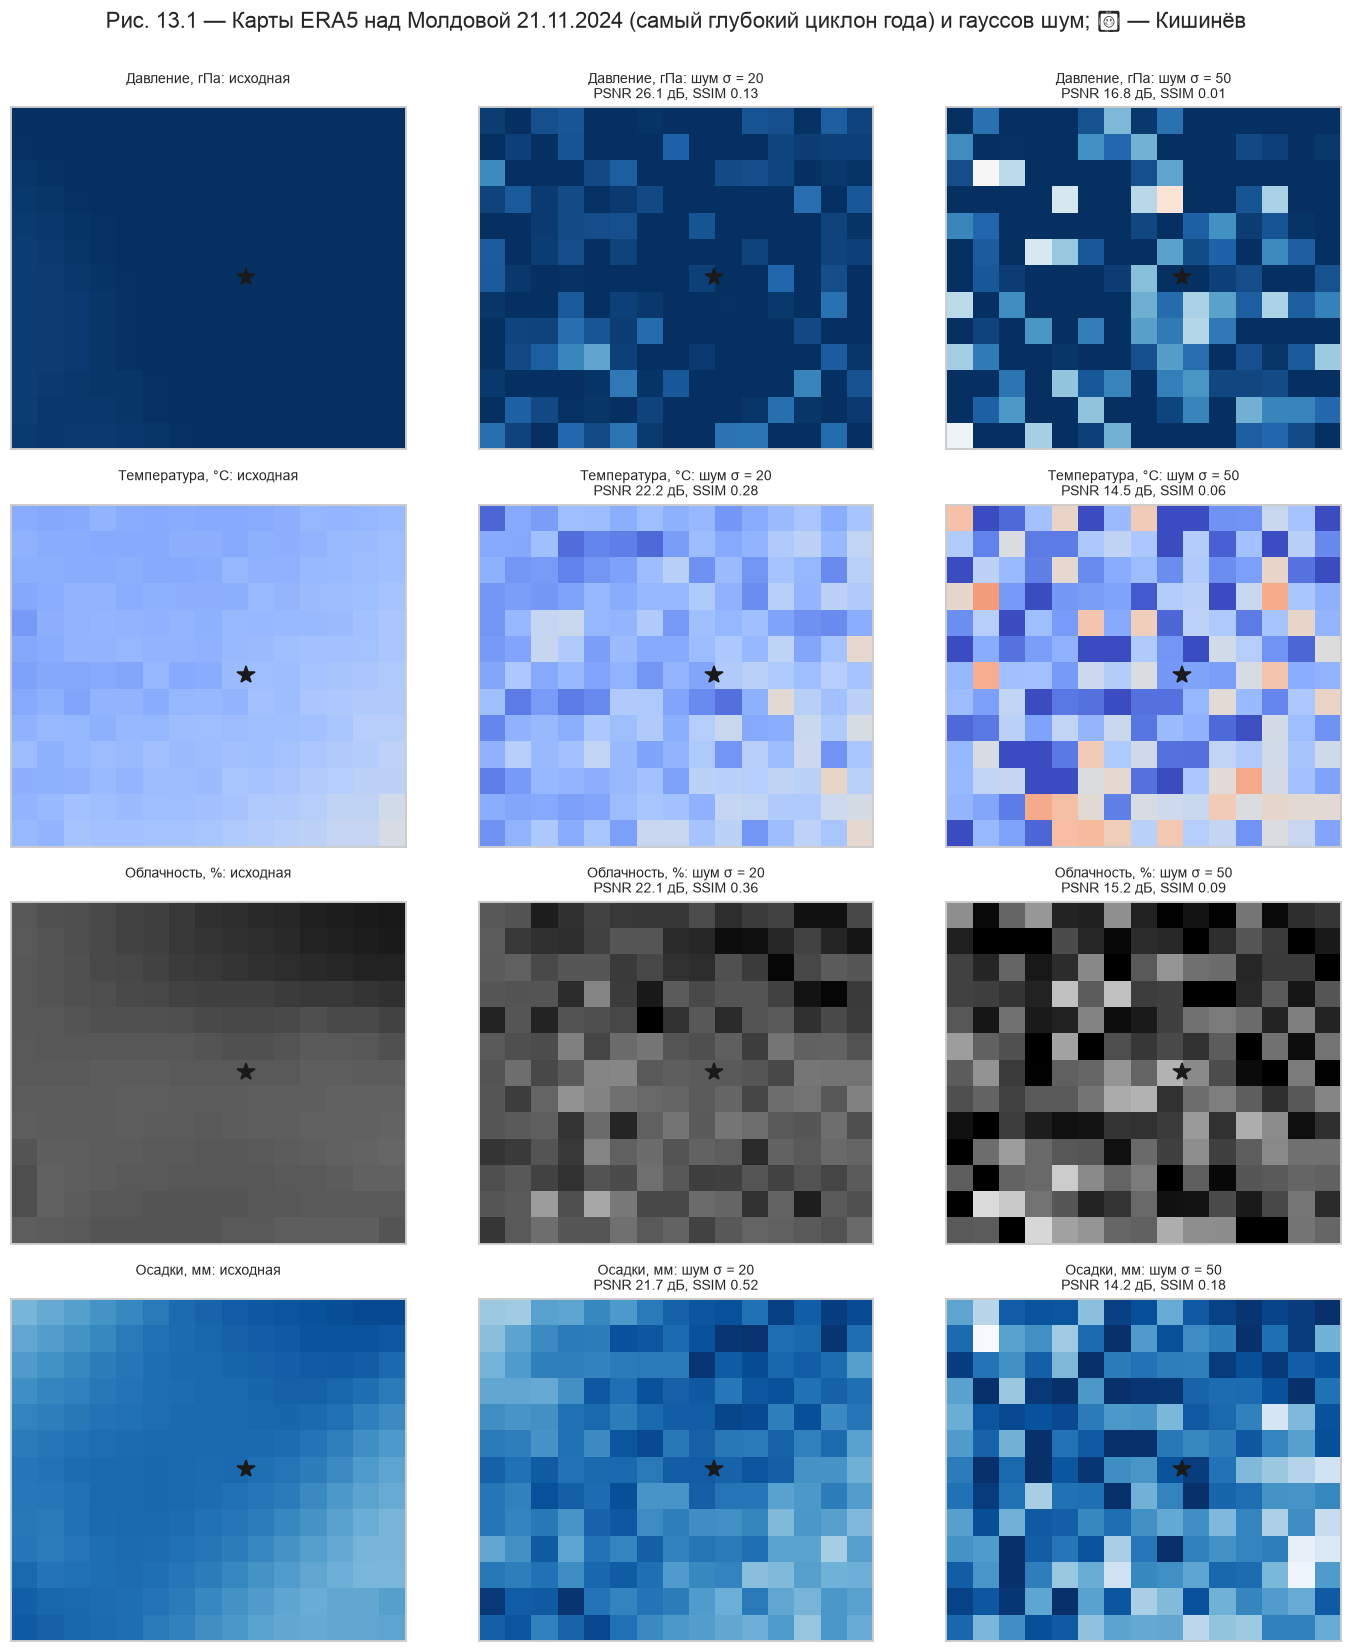

In [2]:
rng = np.random.default_rng(SEED)
day = int(np.argmin(raw["pressure_msl_mean"].min(axis=(1, 2))))          # the deepest cyclone of the year
def add_noise(x, std, rng):
    return np.clip(x + rng.normal(0, std / 255, x.shape), 0, 1)
fig, axes = plt.subplots(4, 3, figsize=(13, 15))
ext = [LON.min() - 0.125, LON.max() + 0.125, LAT.min() - 0.125, LAT.max() + 0.125]
for r, (v, (title, cmap)) in enumerate(VARS.items()):
    clean = IMG[v][day]
    for c, (lab, img) in enumerate([("исходная", clean), ("шум σ = 20", add_noise(clean, 20, rng)), ("шум σ = 50", add_noise(clean, 50, rng))]):
        ax = axes[r, c]; ax.imshow(img, cmap=cmap, extent=ext, vmin=0, vmax=1)
        ax.plot(28.86, 47.01, "k*", ms=12)
        q = f"PSNR {psnr(clean, img, data_range=1):.1f} дБ, SSIM {ssim(clean, img, data_range=1):.2f}" if c else ""
        ax.set_title(f"{title}: {lab}\n{q}", fontsize=9); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"Рис. 13.1 — Карты ERA5 над Молдовой {DATES[day]:%d.%m.%Y} (самый глубокий циклон года) и гауссов шум; ★ — Кишинёв", y=1.0)
plt.tight_layout(); save("fig_13_1_maps_noise")

---
# 2. Классические методы восстановления

- **Gaussian blur** — усреднение по соседям с гауссовыми весами: убирает шум, но размывает всё, включая резкие фронты;
- **Bilateral** — усредняет только соседей, близких и по положению, и **по значению**: сохраняет края;
- **Non-Local Means** — усредняет похожие **фрагменты** по всей карте: сохраняет текстуру, чувствителен к параметру h.

Параметры подобраны на картах обучения (январь–сентябрь), проверка — на 92 картах октября–декабря, у каждой своя реализация шума.

In [3]:
def nlm(x, std, h_mult):
    s = std / 255                       # the noise level is known in this experiment (as in the lab)
    return denoise_nl_means(x, h=h_mult * s, sigma=s, patch_size=3, patch_distance=4, fast_mode=False)
METHODS = {
    "Gaussian blur": (lambda x, std, p: gaussian(x, sigma=p, preserve_range=True), [0.5, 0.75, 1.0, 1.5, 2.0, 2.5, 3.0, 4.0]),
    "Bilateral": (lambda x, std, p: denoise_bilateral(x, sigma_color=p, sigma_spatial=1.0), [0.05, 0.1, 0.2, 0.3, 0.5]),
    "Non-Local Means": (lambda x, std, p: nlm(x, std, p), [0.6, 0.8, 1.0, 1.3, 1.6, 2.0, 2.5, 3.0, 4.0]),
}
def score(clean, rec):
    return psnr(clean, rec, data_range=1), ssim(clean, rec, data_range=1), mse(clean, rec)
best_param, rows = {}, []
for std in (20, 50):
    rng = np.random.default_rng(1)
    tune_days = rng.choice(train_idx, 40, replace=False)
    for name, (f, grid) in METHODS.items():
        res = []
        for p in grid:
            vals = [score(IMG[v][d], f(add_noise(IMG[v][d], std, rng), std, p))[0] for v in VARS for d in tune_days]
            res.append(np.mean(vals))
        best_param[(name, std)] = grid[int(np.argmax(res))]
    rng = np.random.default_rng(2)
    for v in VARS:
        for d in test_idx:
            clean = IMG[v][d]; noisy = add_noise(clean, std, rng)
            rows.append({"σ": std, "Переменная": VARS[v][0], "Метод": "без восстановления", **dict(zip(["PSNR", "SSIM", "MSE"], score(clean, noisy)))})
            for name, (f, grid) in METHODS.items():
                rec = f(noisy, std, best_param[(name, std)])
                rows.append({"σ": std, "Переменная": VARS[v][0], "Метод": name, **dict(zip(["PSNR", "SSIM", "MSE"], score(clean, rec)))})
classic = pd.DataFrame(rows)
print("Подобранные параметры:", {f"{k[0]}, σ={k[1]}": v for k, v in best_param.items()})
classic.groupby(["σ", "Метод"])[["PSNR", "SSIM", "MSE"]].mean().round(3)

Подобранные параметры: {'Gaussian blur, σ=20': 2.0, 'Bilateral, σ=20': 0.1, 'Non-Local Means, σ=20': 4.0, 'Gaussian blur, σ=50': 2.5, 'Bilateral, σ=50': 0.2, 'Non-Local Means, σ=50': 4.0}


PSNR   SSIM    MSE
σ  Метод                                   
20 Bilateral           26.809  0.548  0.003
   Gaussian blur       31.607  0.763  0.001
   Non-Local Means     31.316  0.741  0.001
   без восстановления  22.918  0.324  0.005
50 Bilateral           18.858  0.222  0.015
   Gaussian blur       26.149  0.638  0.003
   Non-Local Means     26.584  0.620  0.003
   без восстановления  15.504  0.110  0.029

---
# 3. Автоэнкодер: метрики по эпохам, скорость обучения, недо- и переобучение

**Denoising-автоэнкодер** — нейросеть, которая получает зашумлённую карту (195 «пикселей»), сжимает её до 32 чисел («суть» карты) и восстанавливает чистую карту. Это MLP 195 → 128 → 32 → 128 → 195 из `scikit-learn`, обучение по эпохам (`partial_fit`). Обучение и проверка разделены по времени: январь–сентябрь против октября–декабря. Все 4 поля обучаются вместе (1 096 карт).

Сравниваются два режима, как в лабе:
- **«Фиксированный шум, мало данных»** — 60 карт с одной и той же реализацией шума: сеть может **запомнить шум**, это путь к переобучению;
- **«Свежий шум каждую эпоху» (аугментация)** — все 1 096 карт обучения, шум генерируется заново на каждой эпохе: запомнить шум невозможно.

Обучение автоэнкодеров: 49 с


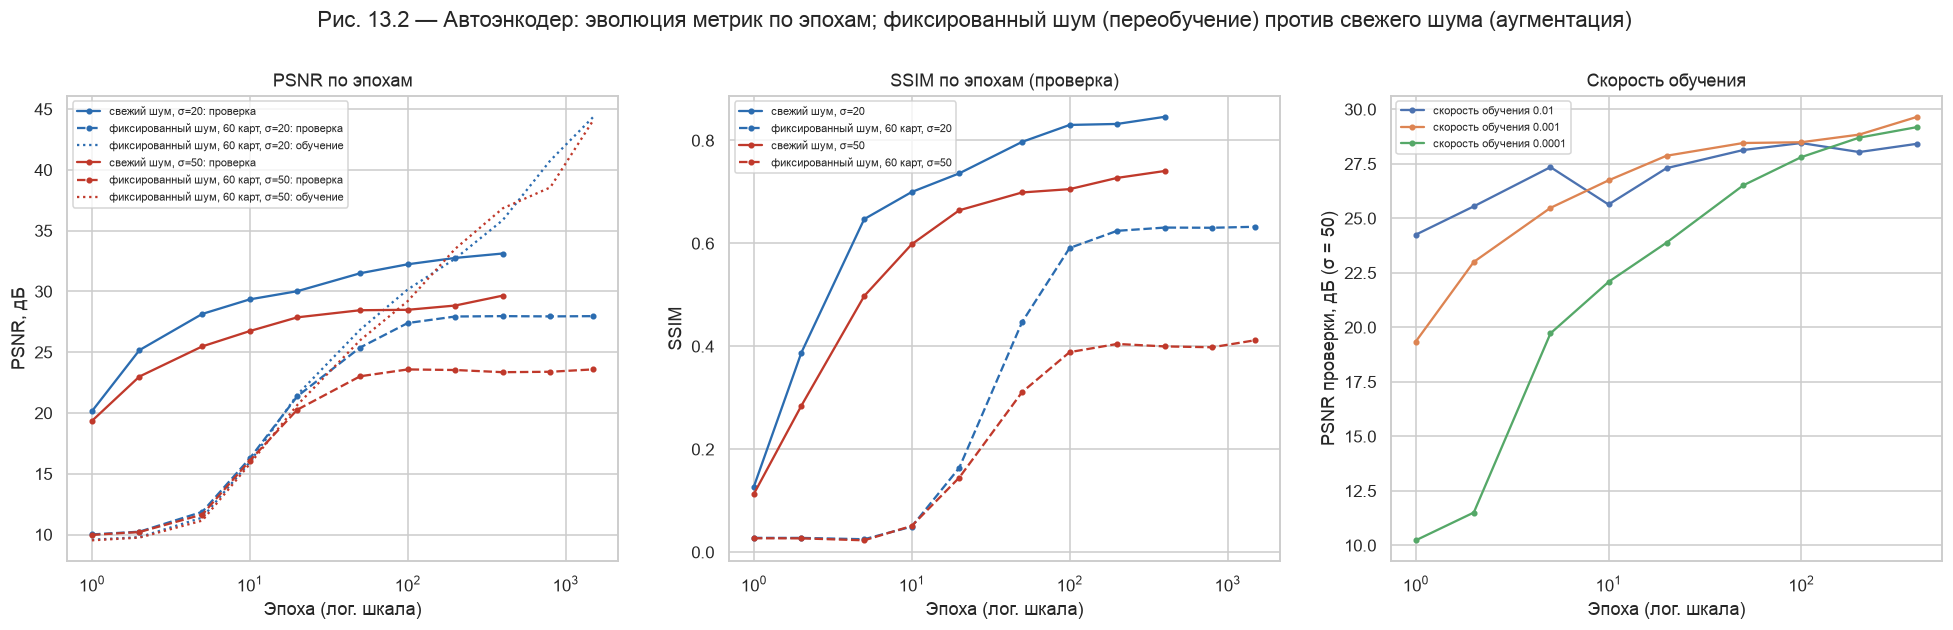

,Режим,σ,Лучшая эпоха (проверка),PSNR проверки: лучший,PSNR проверки: последний,PSNR обучения: последний,SSIM проверки: последний
0,свежий шум,20,400,33.122,33.122,36.735,0.846
1,"фиксированный шум, 60 карт",20,400,27.969,27.969,44.366,0.632
2,свежий шум,50,400,29.657,29.657,32.444,0.741
3,"фиксированный шум, 60 карт",50,1500,23.589,23.589,44.095,0.412


In [4]:
Xc_tr = np.concatenate([IMG[v][train_idx].reshape(len(train_idx), -1) for v in VARS])
Xc_te = np.concatenate([IMG[v][test_idx].reshape(len(test_idx), -1) for v in VARS])
var_te = np.repeat(list(VARS), len(test_idx))
def eval_ae(ae, Xn, Xc):
    R = np.clip(ae.predict(Xn), 0, 1)
    return (np.mean([psnr(c.reshape(H, W_), r.reshape(H, W_), data_range=1) for c, r in zip(Xc, R)]),
            np.mean([ssim(c.reshape(H, W_), r.reshape(H, W_), data_range=1) for c, r in zip(Xc, R)]), float(np.mean((Xc - R) ** 2)))
def train_ae(std, epochs, lr=1e-3, fresh=True, n_train=None, check=(1, 2, 5, 10, 20, 50, 100, 200, 400, 800, 1500), seed=SEED):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(Xc_tr), n_train, replace=False) if n_train else np.arange(len(Xc_tr))
    Xc = Xc_tr[idx]; fixed = add_noise(Xc, std, rng)
    Xn_te = add_noise(Xc_te, std, np.random.default_rng(99))
    ae = MLPRegressor(hidden_layer_sizes=(128, 32, 128), activation="relu", learning_rate_init=lr, batch_size=32,
                      alpha=1e-5, random_state=seed)
    log = []
    for ep in range(1, epochs + 1):
        ae.partial_fit(add_noise(Xc, std, rng) if fresh else fixed, Xc)
        if ep in check or ep == epochs:
            tr = eval_ae(ae, fixed[:200], Xc[:200]); te = eval_ae(ae, Xn_te, Xc_te)
            log.append({"Эпоха": ep, "PSNR обучение": tr[0], "SSIM обучение": tr[1], "PSNR проверка": te[0], "SSIM проверка": te[1], "MSE проверка": te[2]})
    return ae, pd.DataFrame(log)
t = time.time()
runs = {}
for std in (20, 50):
    runs[("свежий шум", std)] = train_ae(std, 400, fresh=True)
    runs[("фиксированный шум, 60 карт", std)] = train_ae(std, 1500, fresh=False, n_train=60)
lr_runs = {lr: train_ae(50, 400, lr=lr, fresh=True)[1] for lr in (1e-2, 1e-3, 1e-4)}
print(f"Обучение автоэнкодеров: {time.time() - t:.0f} с")
fig, axes = plt.subplots(1, 3, figsize=(22, 5.5))
for (mode, std), (ae, log) in runs.items():
    ls = "-" if mode == "свежий шум" else "--"; col = "#2B6CB0" if std == 20 else "#C0392B"
    axes[0].plot(log["Эпоха"], log["PSNR проверка"], ls, color=col, marker="o", ms=3, label=f"{mode}, σ={std}: проверка")
    if mode != "свежий шум":
        axes[0].plot(log["Эпоха"], log["PSNR обучение"], ":", color=col, label=f"{mode}, σ={std}: обучение")
    axes[1].plot(log["Эпоха"], log["SSIM проверка"], ls, color=col, marker="o", ms=3, label=f"{mode}, σ={std}")
for lr, log in lr_runs.items():
    axes[2].plot(log["Эпоха"], log["PSNR проверка"], marker="o", ms=3, label=f"скорость обучения {lr}")
for ax, yl, tl in zip(axes, ["PSNR, дБ", "SSIM", "PSNR проверки, дБ (σ = 50)"], ["PSNR по эпохам", "SSIM по эпохам (проверка)", "Скорость обучения"]):
    ax.set_xscale("log"); ax.set(xlabel="Эпоха (лог. шкала)", ylabel=yl, title=tl); ax.legend(fontsize=7.5)
fig.suptitle("Рис. 13.2 — Автоэнкодер: эволюция метрик по эпохам; фиксированный шум (переобучение) против свежего шума (аугментация)", y=1.02)
save("fig_13_2_autoencoder_epochs")
summary_ae = pd.DataFrame([{"Режим": m, "σ": s, "Лучшая эпоха (проверка)": int(l.loc[l["PSNR проверка"].idxmax(), "Эпоха"]),
                            "PSNR проверки: лучший": l["PSNR проверка"].max(), "PSNR проверки: последний": l["PSNR проверка"].iloc[-1],
                            "PSNR обучения: последний": l["PSNR обучение"].iloc[-1], "SSIM проверки: последний": l["SSIM проверка"].iloc[-1]}
                           for (m, s), (_, l) in runs.items()])
summary_ae.round(3)

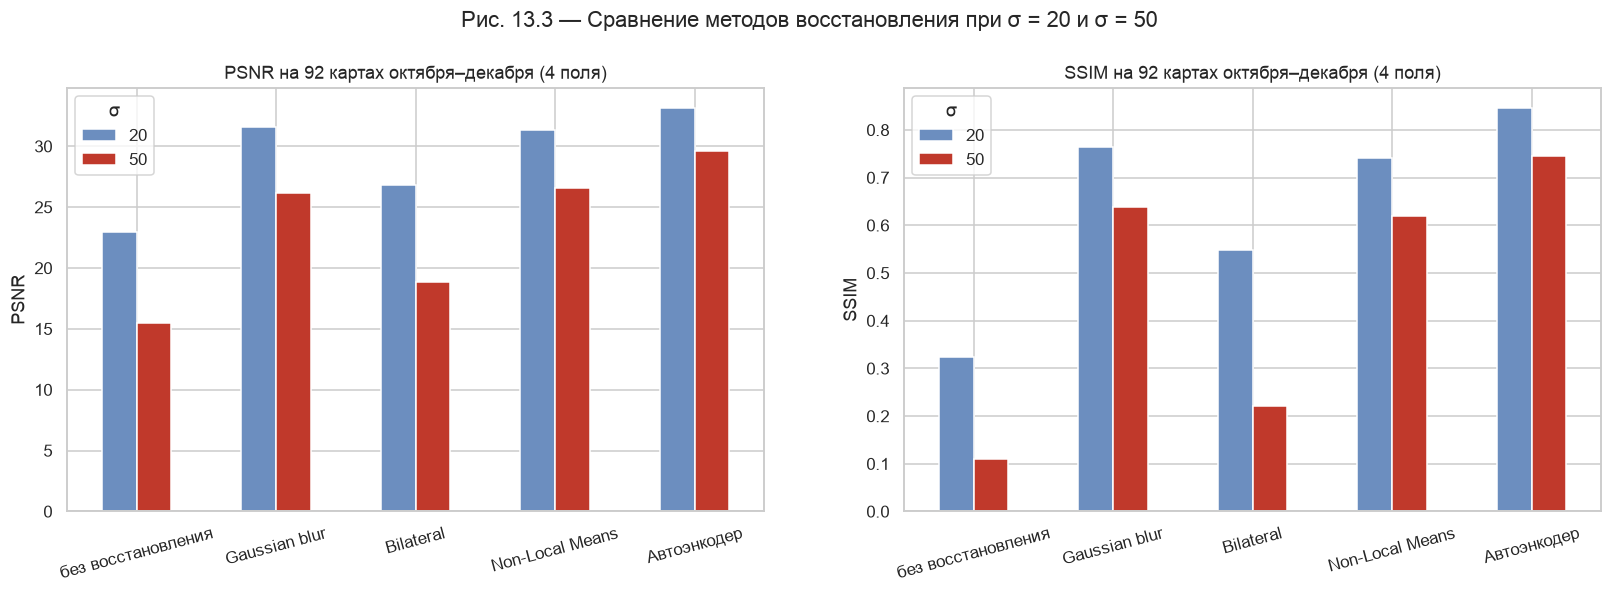

PSNR   SSIM    MSE
σ  Метод                                   
20 Bilateral           26.809  0.548  0.003
   Gaussian blur       31.607  0.763  0.001
   Non-Local Means     31.316  0.741  0.001
   Автоэнкодер         33.132  0.846  0.001
   без восстановления  22.918  0.324  0.005
50 Bilateral           18.858  0.222  0.015
   Gaussian blur       26.149  0.638  0.003
   Non-Local Means     26.584  0.620  0.003
   Автоэнкодер         29.591  0.745  0.002
   без восстановления  15.504  0.110  0.029

In [5]:
rows = []
for std in (20, 50):
    rng = np.random.default_rng(2)
    ae = runs[("свежий шум", std)][0]
    for k, v in enumerate(VARS):
        for d_i, d in enumerate(test_idx):
            clean = IMG[v][d]; noisy = add_noise(clean, std, rng)
            rec = np.clip(ae.predict(noisy.reshape(1, -1)), 0, 1).reshape(H, W_)
            rows.append({"σ": std, "Переменная": VARS[v][0], "Метод": "Автоэнкодер", **dict(zip(["PSNR", "SSIM", "MSE"], score(clean, rec)))})
allm = pd.concat([classic, pd.DataFrame(rows)])
tab = allm.groupby(["σ", "Метод"])[["PSNR", "SSIM", "MSE"]].mean().round(3)
by_var = allm.pivot_table(index=["σ", "Переменная"], columns="Метод", values="SSIM").round(3)
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
order = ["без восстановления", "Gaussian blur", "Bilateral", "Non-Local Means", "Автоэнкодер"]
for ax, metric in zip(axes, ["PSNR", "SSIM"]):
    p = allm.groupby(["Метод", "σ"])[metric].mean().unstack().reindex(order)
    p.plot.bar(ax=ax, color=["#6C8EBF", "#C0392B"], rot=15)
    ax.set(title=f"{metric} на 92 картах октября–декабря (4 поля)", ylabel=metric, xlabel="")
fig.suptitle("Рис. 13.3 — Сравнение методов восстановления при σ = 20 и σ = 50", y=1.02)
save("fig_13_3_methods_compare")
tab

In [6]:
by_var

Метод               Bilateral  Gaussian blur  Non-Local Means  Автоэнкодер  \
σ  Переменная                                                                
20 Давление, гПа        0.518          0.912            0.932        0.878   
   Облачность, %        0.738          0.859            0.795        0.818   
   Осадки, мм           0.457          0.454            0.416        0.768   
   Температура, °C      0.479          0.828            0.821        0.919   
50 Давление, гПа        0.127          0.771            0.789        0.802   
   Облачность, %        0.409          0.746            0.690        0.725   
   Осадки, мм           0.241          0.326            0.293        0.635   
   Температура, °C      0.110          0.708            0.709        0.817   

Метод               без восстановления  
σ  Переменная                           
20 Давление, гПа                 0.181  
   Облачность, %                 0.529  
   Осадки, мм                    0.359  
   Температура, °C               0.226  
50 Давление, гПа                 0.039  
   Облачность, %                 0.210  
   Осадки, мм                    0.143  
   Температура, °C               0.050

**Интерпретация (части 2–3).**

**Классические фильтры (рис. 13.3).**
- На погодных картах **лучшие — гауссово размытие и NLM**: при σ = 20 PSNR 31.6 и 31.3 дБ (без восстановления 22.9), при σ = 50 — 26.1 и 26.6 дБ (15.5).
- **Билатеральный фильтр — худший** (26.8 и 18.9 дБ). Он сохраняет «края», то есть резкие перепады значений, а на зашумлённой гладкой карте самые резкие перепады создаёт сам шум. Фильтр сохраняет шум как «края».
- Это противоположно ожиданию лабы («bilateral хорош при малом шуме»): там фотографии с настоящими краями, а поля давления и температуры **гладкие**.
- Лучший параметр NLM оказался на краю сетки (h = 4σ, очень сильное усреднение): для гладких полей NLM вырождается в обычное сглаживание, и его преимущество — сохранение текстуры — здесь не нужно.

**Автоэнкодер — лучший метод.**
- PSNR 33.1 / 29.6 дБ, SSIM 0.85 / 0.75 при σ = 20 / 50.
- Сильнее всего он выигрывает на **осадках**: SSIM 0.64 против 0.29–0.33 у фильтров при σ = 50. Поле осадков пятнистое, и фильтр не отличает дождевое пятно от шума, а автоэнкодер за 274 дня обучения «выучил», какими бывают реальные поля осадков. Это и есть мысль лабы: *автоэнкодер не фильтрует, а восстанавливает из памяти о данных*.
- На облачности гауссов фильтр чуть лучше (SSIM 0.75 против 0.73).

**Эпохи, недо- и переобучение (рис. 13.2).**
- **Недообучение:** на первых эпохах сеть ещё не выучила структуру. При σ = 20 после 1-й эпохи PSNR 20.1 дБ — хуже шумной карты (22.9). В режиме «60 карт» на 1–5 эпохах PSNR 10–12 дБ — хуже шумной карты при обоих уровнях шума (22.9 и 15.5).
- **Переобучение:** при фиксированном шуме на 60 картах PSNR **обучения** растёт до 44 дБ, а **проверки** с ~100-й эпохи стоит на 28.0 (σ = 20) и 23.6 дБ (σ = 50). Разрыв в 16–20 дБ означает, что сеть запомнила конкретные реализации шума на обучающих картах. У нас переобучение видно как растущий разрыв, а не как падение проверки — в лабе оно тоже проявлялось в основном так.
- **Свежий шум каждую эпоху** (аугментация + все 1 096 карт) даёт +5–6 дБ на проверке при разрыве всего 3 дБ: запомнить шум невозможно, приходится учить структуру.
- **Скорость обучения:** 0.01 быстро растёт, но «скачет» (провалы на 10-й и 200-й эпохах); 0.001 даёт лучший итог (29.6 дБ к 400-й эпохе); 0.0001 стабильна, но медленна (29.2 дБ). Это подтверждает таблицу лабы «0.001 — разумный баланс».

---
# 4. «Что теряется? Что сохраняется?» — метрики против метеорологического смысла

PSNR и SSIM оценивают всю карту целиком. Синоптику важны **конкретные структуры**:
- **градиент давления** — перепад давления на 100 км, он определяет силу ветра: сохранился ли он после сглаживания (отношение восстановленного к истинному);
- **давление в Кишинёве** — ошибка в гПа (сдвиг барометра на 6 гПа в ноутбуках 04 и 10 уже заметно менял прогноз);
- **очаг осадков** — максимум осадков на карте (сохранился ли пик или размыт);
- **«дождь/сухо» в Кишинёве** — главное для нашей задачи: правильно ли восстановлено, были ли осадки ≥ 1 мм в точке Кишинёва.

σ = 50; дней проверки: 92; дней с пиком осадков ≥ 5 мм: 27


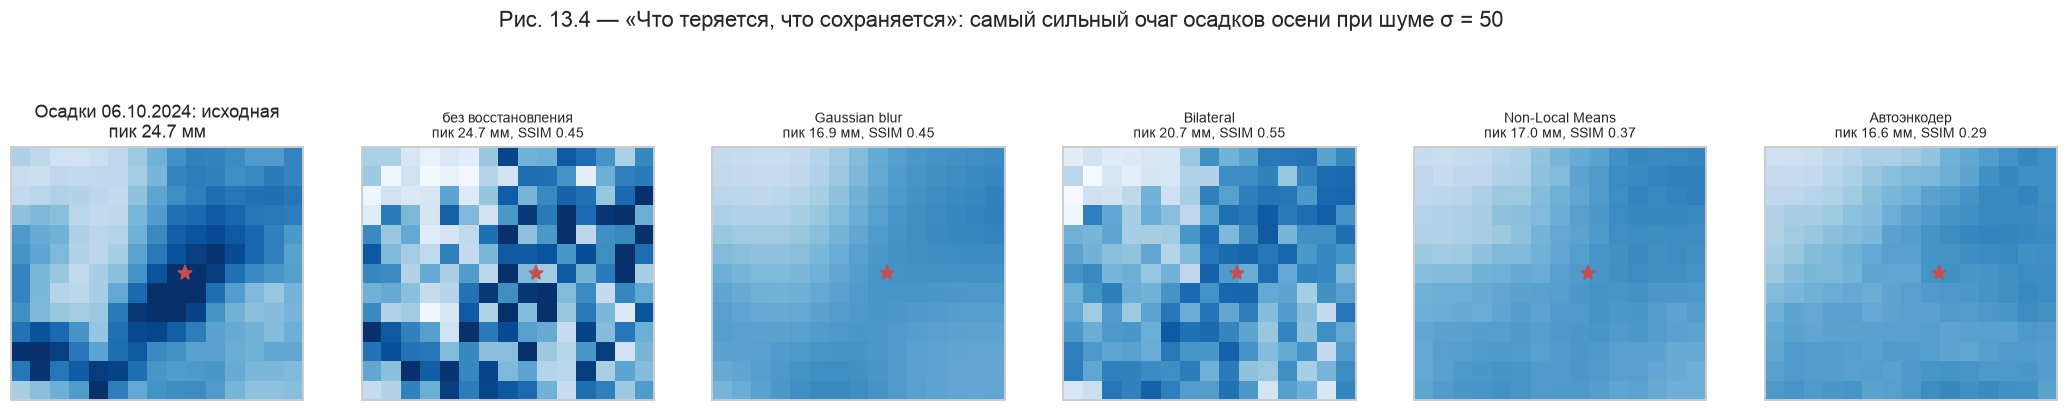

,Градиент давления: восстановлено / истинно,"Ошибка давления в Кишинёве, гПа",Пик осадков: восстановлено / истинно,Кишинёв «дождь/сухо» верно,SSIM осадков
Метод,,,,,
без восстановления,35.580,5.943,1.610,0.804,0.137
Gaussian blur,2.364,0.843,0.657,0.989,0.326
Bilateral,21.834,2.860,1.020,0.946,0.230
Non-Local Means,2.393,0.874,0.576,0.989,0.293
Автоэнкодер,2.076,0.547,0.718,1.000,0.628


In [7]:
ich, jch = int(np.argmin(np.abs(LAT - 47.0))), int(np.argmin(np.abs(LON - 28.75)))
def km(i1, j1, i2, j2):
    return np.hypot((i1 - i2) * 0.25 * 111, (j1 - j2) * 0.25 * 111 * np.cos(np.deg2rad(47)))
std = 50
rng = np.random.default_rng(5)
ae = runs[("свежий шум", std)][0]
recon = {"без восстановления": lambda x: x, "Gaussian blur": lambda x: METHODS["Gaussian blur"][0](x, std, best_param[("Gaussian blur", std)]),
         "Bilateral": lambda x: METHODS["Bilateral"][0](x, std, best_param[("Bilateral", std)]),
         "Non-Local Means": lambda x: METHODS["Non-Local Means"][0](x, std, best_param[("Non-Local Means", std)]),
         "Автоэнкодер": lambda x: np.clip(ae.predict(x.reshape(1, -1)), 0, 1).reshape(H, W_)}
rows = []
for d in test_idx:
    pc, rc = IMG["pressure_msl_mean"][d], IMG["precipitation_sum"][d]
    pn, rn = add_noise(pc, std, rng), add_noise(rc, std, rng)
    p_true = from_img("pressure_msl_mean", pc)
    gy, gx = np.gradient(p_true, 0.25 * 111, 0.25 * 111 * np.cos(np.deg2rad(47)))   # hPa per km
    grad_true = np.hypot(gx, gy).mean() * 100
    rain_true = from_img("precipitation_sum", rc[ich, jch]) >= 1
    peak_true = from_img("precipitation_sum", rc).max()
    for name, f in recon.items():
        pr, rr = f(pn), f(rn)
        p_rec = from_img("pressure_msl_mean", pr)
        gy, gx = np.gradient(p_rec, 0.25 * 111, 0.25 * 111 * np.cos(np.deg2rad(47)))
        rows.append({"Метод": name, "Градиент давления: восстановлено / истинно": np.hypot(gx, gy).mean() * 100 / grad_true,
                     "Ошибка давления в Кишинёве, гПа": abs(p_rec[ich, jch] - p_true[ich, jch]),
                     "Пик осадков: восстановлено / истинно": from_img("precipitation_sum", rr).max() / peak_true if peak_true >= 5 else np.nan,
                     "Кишинёв «дождь/сухо» верно": (from_img("precipitation_sum", rr[ich, jch]) >= 1) == rain_true,
                     "SSIM осадков": ssim(rc, rr, data_range=1)})
loss = pd.DataFrame(rows).groupby("Метод").mean().reindex(list(recon)).round(3)
R = pd.DataFrame(rows)
print(f"σ = {std}; дней проверки: {len(test_idx)}; дней с пиком осадков ≥ 5 мм: {int(R['Пик осадков: восстановлено / истинно'].notna().sum() / len(recon))}")
d_show = test_idx[int(np.argmax([from_img('precipitation_sum', IMG['precipitation_sum'][d]).max() for d in test_idx]))]
rng = np.random.default_rng(7)
noisy = add_noise(IMG["precipitation_sum"][d_show], std, rng)
fig, axes = plt.subplots(1, 6, figsize=(24, 4.3))
axes[0].imshow(from_img("precipitation_sum", IMG["precipitation_sum"][d_show]), cmap="Blues", extent=ext, vmin=0)
axes[0].set_title(f"Осадки {DATES[d_show]:%d.%m.%Y}: исходная\nпик {from_img('precipitation_sum', IMG['precipitation_sum'][d_show]).max():.1f} мм")
for ax, (name, f) in zip(axes[1:], recon.items()):
    r = from_img("precipitation_sum", f(noisy))
    ax.imshow(r, cmap="Blues", extent=ext, vmin=0, vmax=from_img("precipitation_sum", IMG["precipitation_sum"][d_show]).max())
    ax.set_title(f"{name}\nпик {r.max():.1f} мм, SSIM {ssim(IMG['precipitation_sum'][d_show], f(noisy), data_range=1):.2f}", fontsize=9)
for ax in axes: ax.plot(28.86, 47.01, "r*", ms=10); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Рис. 13.4 — «Что теряется, что сохраняется»: самый сильный очаг осадков осени при шуме σ = 50", y=1.05)
save("fig_13_4_what_is_lost")
loss

**Интерпретация (часть 4).**

**Ответ на вопрос лабы «Что теряется? Что сохраняется?» (σ = 50, 92 дня октября–декабря):**
- **Сохраняется то, что нужно нашей задаче:** «дождь/сухо» в точке Кишинёва автоэнкодер восстанавливает **в 100 %** дней, гауссов фильтр и NLM — в 98.9 %, без восстановления — лишь в 80 %. Давление в Кишинёве восстанавливается с ошибкой 0.55 гПа (автоэнкодер) против 5.9 гПа на шумной карте.
- **Теряются пики:** у 27 дней с очагом осадков ≥ 5 мм восстановленный максимум составляет 58–72 % истинного (NLM 0.58, гауссов 0.66, автоэнкодер 0.72). Сильный ливень после восстановления выглядит слабее. Для предупреждений о критической погоде (≥ 10 мм) это опасно.
- **Обманчивая метрика.** У билатерального фильтра отношение пиков 1.02 выглядит идеально, но только потому, что он **не убрал шум** (SSIM осадков 0.23). Шум случайно создаёт столь же высокие пики: на шумной карте отношение 1.61.
- **Невосстановимое — градиент давления**, то есть «ветер». После любого метода средний перепад давления на 100 км **завышен в 2.1–2.4 раза** (на шумной карте — в 36 раз). Производная усиливает остаточный шум, и даже карта с SSIM 0.80 даёт неверную силу ветра.
- **Вывод «метрики — линейки, а не глаза» (из лабы):** PSNR и SSIM честно описывают сходство всей карты, но не говорят, сохранились ли пики и градиенты, по которым принимаются решения. Поэтому качество восстановления надо проверять **метрикой задачи**: «дождь/сухо», ошибка в гПа, отношение пиков. Решение (сделали X, потому что Y): для тревог о критических осадках сглаженную карту не используем, нужен исходный сигнал и контроль датчика (ноутбуки 04 и 10).

---
# 5. Аугментация в признаках: помогает ли она нашей модели дождя?

Лаба различает аугментацию **в изображениях** (видимую — повороты, шум) и **в признаках** (невидимую — шум в векторах, mixup, выпадение признаков) и предупреждает о «неконтролируемой» аугментации. Проверяем три вида аугментации признаков на модели осадков (26 признаков, Кишинёв): к обучающим дням добавляются искусственные копии.
- **шум** — копия + гауссов шум 0.3 ст. откл. каждого признака;
- **mixup внутри класса** — смесь двух дней **одного** класса (λ ~ Beta(0.4, 0.4)) — родственник SMOTE из ноутбука 03;
- **выпадение признаков** — у копии 20 % признаков заменены средним (имитация отказа датчика).

Оценка — на тесте 2024–2025 в двух условиях: исправные датчики и шум 0.5σ на 4 датчиках (сценарий ноутбука 09). Модели — Random Forest и Elastic Net (с параметрами из ноутбуков 02 и 09).

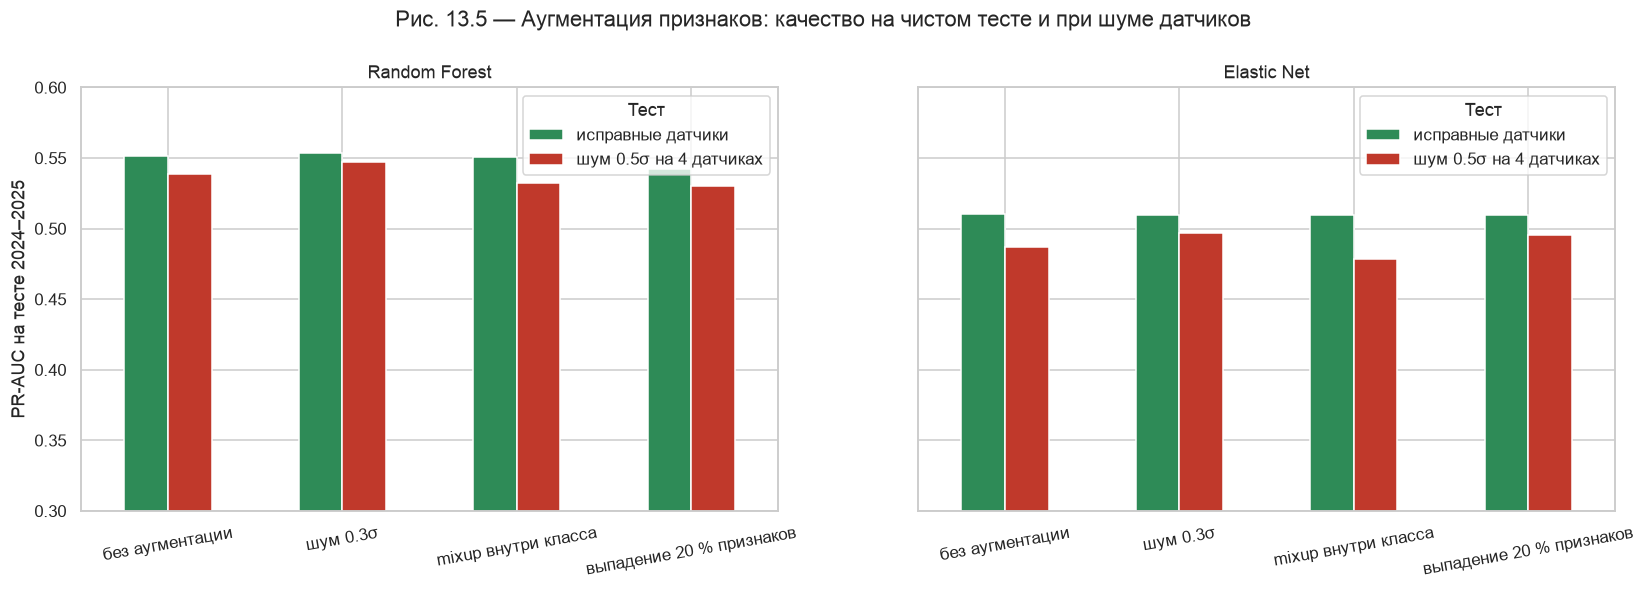

PR-AUC  \
Тест                                   исправные датчики   
Модель        Аугментация                                  
Elastic Net   mixup внутри класса                  0.510   
              без аугментации                      0.510   
              выпадение 20 % признаков             0.509   
              шум 0.3σ                             0.510   
Random Forest mixup внутри класса                  0.551   
              без аугментации                      0.551   
              выпадение 20 % признаков             0.542   
              шум 0.3σ                             0.553   

                                                               \
Тест                                   шум 0.5σ на 4 датчиках   
Модель        Аугментация                                       
Elastic Net   mixup внутри класса                       0.478   
              без аугментации                           0.487   
              выпадение 20 % признаков                  0.495   
              шум 0.3σ                                  0.497   
Random Forest mixup внутри класса                       0.533   
              без аугментации                           0.539   
              выпадение 20 % признаков                  0.530   
              шум 0.3σ                                  0.547   

                                                 ROC-AUC  \
Тест                                   исправные датчики   
Модель        Аугментация                                  
Elastic Net   mixup внутри класса                  0.786   
              без аугментации                      0.793   
              выпадение 20 % признаков             0.789   
              шум 0.3σ                             0.791   
Random Forest mixup внутри класса                  0.791   
              без аугментации                      0.793   
              выпадение 20 % признаков             0.789   
              шум 0.3σ                             0.791   

                                                               
Тест                                   шум 0.5σ на 4 датчиках  
Модель        Аугментация                                      
Elastic Net   mixup внутри класса                       0.759  
              без аугментации                           0.770  
              выпадение 20 % признаков                  0.767  
              шум 0.3σ                                  0.768  
Random Forest mixup внутри класса                       0.774  
              без аугментации                           0.776  
              выпадение 20 % признаков                  0.769  
              шум 0.3σ                                  0.773

In [8]:
from db import load_dataset, load_daily
from features import FEATURES, TARGET, build_features
from regularization import make_model, add_sensor_noise
from sklearn.base import clone
from sklearn.metrics import average_precision_score, roc_auc_score
data = load_dataset("chisinau"); tr = data[data.date.dt.year <= 2022]; te = data[data.date.dt.year >= 2024]
noisy_te = build_features(add_sensor_noise(load_daily("chisinau"), sigma=0.5, start="2024-01-01")); noisy_te = noisy_te[noisy_te.date.dt.year >= 2024]
Xtr, ytr = tr[FEATURES].to_numpy(), tr[TARGET].to_numpy()
sd, mu = Xtr.std(0), Xtr.mean(0)
def augment(kind, rng, copies=1):
    if kind == "без аугментации": return Xtr, ytr
    Xs, ys = [Xtr], [ytr]
    for _ in range(copies):
        if kind == "шум 0.3σ":
            Xa = Xtr + rng.normal(0, 0.3, Xtr.shape) * sd
        elif kind == "mixup внутри класса":
            Xa = Xtr.copy()
            for c in (0, 1):
                idx = np.where(ytr == c)[0]; partner = rng.permutation(idx)
                lam = rng.beta(0.4, 0.4, len(idx))[:, None]
                Xa[idx] = lam * Xtr[idx] + (1 - lam) * Xtr[partner]
        elif kind == "выпадение 20 % признаков":
            Xa = Xtr.copy(); mask = rng.random(Xtr.shape) < 0.2; Xa[mask] = np.broadcast_to(mu, Xtr.shape)[mask]
        Xs.append(Xa); ys.append(ytr)
    return np.vstack(Xs), np.concatenate(ys)
rf = joblib.load(ROOT / "models" / "baseline_model.joblib")["model"]
b = joblib.load(ROOT / "models" / "regularization_best.joblib")["Elastic Net"]
rows = []
for kind in ["без аугментации", "шум 0.3σ", "mixup внутри класса", "выпадение 20 % признаков"]:
    Xa, ya = augment(kind, np.random.default_rng(SEED))
    for mname, model in [("Random Forest", clone(rf).set_params(n_jobs=-1)), ("Elastic Net", make_model(b["C"], b["l1_ratio"]))]:
        m = model.fit(pd.DataFrame(Xa, columns=FEATURES), ya)
        for cond, T in [("исправные датчики", te), ("шум 0.5σ на 4 датчиках", noisy_te)]:
            p = m.predict_proba(T[FEATURES])[:, 1]
            rows.append({"Модель": mname, "Аугментация": kind, "Тест": cond, "ROC-AUC": roc_auc_score(T[TARGET], p),
                         "PR-AUC": average_precision_score(T[TARGET], p)})
aug = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(18, 5), sharey=True)
for ax, mname in zip(axes, ["Random Forest", "Elastic Net"]):
    pv = aug[aug["Модель"] == mname].pivot(index="Аугментация", columns="Тест", values="PR-AUC").reindex(
        ["без аугментации", "шум 0.3σ", "mixup внутри класса", "выпадение 20 % признаков"])
    pv.plot.bar(ax=ax, rot=10, color=["#2E8B57", "#C0392B"])
    ax.set(title=mname, ylabel="PR-AUC на тесте 2024–2025", xlabel="", ylim=(0.3, 0.6))
fig.suptitle("Рис. 13.5 — Аугментация признаков: качество на чистом тесте и при шуме датчиков", y=1.02)
save("fig_13_5_feature_augmentation")
aug.pivot_table(index=["Модель", "Аугментация"], columns="Тест", values=["PR-AUC", "ROC-AUC"]).round(3)

**Интерпретация (часть 5).**

- **Аугментация признаков почти не влияет на качество при исправных датчиках:** PR-AUC меняется в пределах ±0.01 (RF: 0.551 → 0.553 с шумом; 0.542 с выпадением признаков).
- **При шуме датчиков аугментация шумом слегка помогает:** RF 0.539 → 0.547, Elastic Net 0.487 → 0.497. Модель, обученная на «грязных» копиях, меньше доверяет каждому отдельному значению. Это тот же принцип, что «свежий шум» для автоэнкодера, только в признаках.
- **Mixup вредит при шуме** (RF 0.533, ENet 0.478). Смесь двух дней одного класса может оказаться **физически невозможным днём**: полузимний-полулетний, с давлением одного дня и облачностью другого. Это пример «неконтролируемой аугментации» из лабы: модель учится на днях, которых не бывает. Та же причина, по которой синтетика SMOTE отличалась от реальных дней в ноутбуке 03 (adversarial AUC 0.74).
- **Выпадение признаков** помогает линейной модели при шуме (0.487 → 0.495) и чуть вредит лесу. Лес и так устойчив к отсутствию одного признака: у него много деревьев на разных признаках.
- **Вывод:** аугментация признаков — слабый и выборочный инструмент для наших данных. Сильнее работают выбор силы регуляризации (ноутбук 09) и контроль датчиков (ноутбуки 04 и 10). Если применять, то шум в признаках — «контролируемая» аугментация, имитирующая реальные ошибки датчиков. Mixup на погодных днях не применять.

---
# 6. Аугментация данных против RAG и ответы на вопросы лабы

**Аугментация данных и RAG — разные инструменты** (раздел лабы о «путанице понятий»):

| | Аугментация данных | RAG (Retrieval-Augmented Generation) |
|---|---|---|
| Где | обучение модели (изображения, признаки) | ответ языковой модели (LLM) |
| Что добавляется | **искусственные** варианты существующих данных (шум, повороты, mixup) | **реальная** внешняя информация, найденная по смыслу запроса |
| Когда | до или во время обучения | в момент ответа |
| Цель | обобщение, устойчивость | точность и актуальность ответа |
| Риск | «неконтролируемая» аугментация создаёт несуществующие объекты (mixup погодных дней) | поиск только в заранее настроенном источнике; плохой источник — плохой ответ |

**Аналогия в нашем проекте.**
- Обучение автоэнкодера на «свежем шуме» и модели дождя на зашумлённых копиях — это **аугментация**.
- Сервис тревог RTAP (ноутбук 10), который в момент решения **берёт данные соседних станций**, — ближе по духу к **retrieval**: недостающее значение (пропавшее направление ветра, опоздавшая запись) не придумывается, а **находится** в другом реальном источнике за тот же день. Признаки соседей в модели (+0.02 PR-AUC у Random Forest) — тот же принцип «дополнить решение внешним реальным контекстом».

**Ответы на вопросы лабы**

1. **Что такое «неконтролируемая аугментация» и «навязчивая оптимизация»?** — Первая создаёт данные, которых не бывает в реальности (mixup дней разных сезонов). Вторая подгоняет параметры до идеальной метрики обучения (PSNR 44 дБ на 60 картах). Обе ведут к переобучению: в одном случае модель учится на несуществующем, в другом запоминает конкретный шум.
2. **Применяется ли аугментация к признакам и чем она «странна»?** — Да (раздел 5). Она невидима: зашумлённый вектор признаков не покажешь как картинку. Поэтому проверять её можно только качеством на реальных данных — у нас шум помог слабо, mixup навредил.
3. **Что отражают PSNR, SSIM, MSE?** — PSNR и MSE — среднюю попиксельную близость, SSIM — сохранение структуры (у нас лучше всего различал методы на осадках: 0.64 против 0.3). Ни одна не говорит о пиках и градиентах (раздел 4).
4. **Правильно ли метрики описывают процесс?** — Рост метрик по эпохам честно показывает обучение. Но на 60 картах PSNR обучения 44 дБ — это запоминание шума, а не качество. Судить можно только по проверке на картах, которых модель не видела.
5. **Как связаны эпохи, скорость обучения и переобучение?** — Мало эпох — недообучение (хуже шумной карты). Много эпох на малых данных с фиксированным шумом — переобучение (разрыв 16–20 дБ). Скорость 0.01 нестабильна, 0.001 — оптимум, 0.0001 медленна.
6. **Как предотвратить переобучение?** — Больше данных и **свежий шум** каждую эпоху (дал +5–6 дБ), L2-штраф весов, остановка по проверочной выборке, более простая сеть.
7. **Какое восстановление «сохраняет душу изображения»?** — Для давления и температуры — автоэнкодер и гауссов фильтр (SSIM ≈ 0.8, ошибка давления 0.5–0.8 гПа). Для осадков — автоэнкодер (SSIM 0.64, «дождь/сухо» 100 %), но он занижает пики на 28 %. «Душа» погодной карты — не пиксели, а **решения, которые по ней принимаются**. Поэтому выбор метода зависит от вопроса: «будет ли дождь» — автоэнкодер; «будет ли ливень ≥ 10 мм» — ни один метод, только исходные данные и контроль датчика.

**Обнаружить → смоделировать → снизить (лаб. 4)**

| Фактор | Обнаружили | Смоделировали | Снизили |
|---|---|---|---|
| Шум на картах | PSNR 15.5 / SSIM 0.11 при σ = 50 | гауссов шум σ = 20 / 50 | автоэнкодер: 29.6 дБ / 0.75; «дождь/сухо» 100 % |
| Переобучение автоэнкодера | разрыв обучение–проверка 16–20 дБ | фиксированный шум на 60 картах | свежий шум каждую эпоху + все карты: разрыв 3 дБ |
| Потеря пиков и градиентов | пики −28…−42 %, градиент ×2 | метрики задачи вместо PSNR | для тревог об экстремумах — исходные данные + контроль датчика |
| Шум в признаках модели дождя | PR-AUC 0.551 → 0.539 | шум 0.5σ на 4 датчиках | аугментация шумом: 0.547; mixup отвергнут (0.533) |

In [9]:
out = ROOT / "data" / "processed"
allm.groupby(["σ", "Метод", "Переменная"])[["PSNR", "SSIM", "MSE"]].mean().reset_index().to_csv(out / "lab4_denoising_metrics.csv", index=False)
aug.to_csv(out / "lab4_feature_augmentation.csv", index=False)
print("Сохранено: data/processed/lab4_*.csv")

Сохранено: data/processed/lab4_*.csv
